# ISPC examples using google colab

This notebook provides application examples to showcase the ISPC compiler. For each example it is possible to edit the kernel files and run the whole application. In most cases, it will report the kernel(s) execution time.

## The language

ISPC is a C-based language, with custom extensions. By default you can write code using C89 constructs. Please, refer to the documentation for the complete lists of extensions: [https://ispc.github.io/ispc.html](https://ispc.github.io/ispc.html)


## How to use it

All the example have the same structure: we use a simple Makefile to drive the compilation process. You can use the cells below to compile and run example. If you want to play, you can edit any source files in colab by clicking on the folder icon on the left toolbar.
> Before running any experiment, you need to set up the environment.

## Setup

These step are required to initialize the environment.

### Step 1 - Check the available CPU

All the examples in this colab assume that we have two cores with AVX2 capabilities. Please double-check that the hardware is still the same.

In [ ]:
!lscpu

### Step 2 - Prepare the environment

The following cell will download the ISPC compiler and the example source code.

In [7]:
!if [ ! -d "ispc" ]; then wget https://github.com/ispc/ispc/releases/download/v1.21.0/ispc-v1.21.0-linux.tar.gz && tar -xf ispc-v1.21.0-linux.tar.gz && mv ispc-v1.21.0-linux ispc && rm ispc-v1.21.0-linux.tar.gz; fi
%env PATH = /content/ispc/bin/:opt/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/tools/node/bin:/tools/google-cloud-sdk/bin
!if [ ! -d "sinx" ]; then wget -O examples.tar.gz https://drive.google.com/uc?id=1ErE7RQVKSAkhkqIWzIb1eWKqV-IwiLE7 && tar -xf examples.tar.gz && rm examples.tar.gz; fi

env: PATH=/content/ispc/bin/:opt/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/tools/node/bin:/tools/google-cloud-sdk/bin


This command will delete the source code of all the examples (if you want to start over again with your modifications). Use the previous cell to reinitialize the environment.

In [ ]:
!rm -rf count_gt4/ mandelbrot/ matmul/ sinx/ sinx_vec/

## sin(x) example

We compare the ISPC compiler vs a naive CPP implementation.

In [ ]:
!make -C /content/sinx clean
!make -C /content/sinx
!/content/sinx/main 2>&1

Now we compare the ISPC compiler vs a CPP source with the loop unrolled to expose more directly to the compiler the optimization opportunities.

In [ ]:
!make -C /content/sinx_vec clean
!make -C /content/sinx_vec
!/content/sinx_vec/main 2>&1

## Count elements example

We write a program that counts how many elements in a vector are greater than a threshold. A first implementation uses low-level primitives to communicate between the program instances. While a second implementation uses the high-level interface to perform the reduction.

In [ ]:
!make -C /content/count_gt4 clean
!make -C /content/count_gt4
!/content/count_gt4/main 2>&1

> Prefer the high-level reduction usage. Fallback to the low-level primitives to implement custom communications.

## Matrix multiplication example

With this example, we introduce *tasks*. We compare a first serial version of matrix multiplication against one that can scale across the available CPUs. We use the file `/content/ispc/examples/common/tasksys.cpp` to map tasks with system threads.

In [5]:
!make -C /content/matmul clean
!make -C /content/matmul
!/content/matmul/main 2>&1

make: Entering directory '/content/matmul'
make: Leaving directory '/content/matmul'
make: Entering directory '/content/matmul'
	ISPC	kernel_serial.ispc
	ISPC	kernel_task.ispc
	CXX	tasksys.cpp
	CXX	main.cpp
	GEN	main
make: Leaving directory '/content/matmul'
[ function ispc::matmul_serial took 24363921214ns ]
[ function ispc::matmul_task took 22436543240ns ]


## Mandelbrot example

Let's try to apply all the concepts that we have seen previously with a more fun application: draw the mandelbrot set. This first command will generate the output images using the different kernels.

In [6]:
!make -C /content/mandelbrot clean
!make -C /content/mandelbrot
!/content/mandelbrot/main 2>&1

make: Entering directory '/content/mandelbrot'
make: Leaving directory '/content/mandelbrot'
make: Entering directory '/content/mandelbrot'
	ISPC	kernel_serial.ispc
	ISPC	kernel_task.ispc
	CXX	tasksys.cpp
	CXX	kernel_cpp.cpp
	CXX	main.cpp
	GEN	main
make: Leaving directory '/content/mandelbrot'
[ function cpp::mandelbrot took 82026784ns ]
[ function cpp::mandelbrot took 82441383ns ]
[ function cpp::mandelbrot took 81583903ns ]
[ function ispc::mandelbrot took 14317033ns ]
[ function ispc::mandelbrot took 14468592ns ]
[ function ispc::mandelbrot took 15459563ns ]
[ function ispc::mandelbrot_task took 8989942ns ]
[ function ispc::mandelbrot_task took 8865531ns ]
[ function ispc::mandelbrot_task took 8958162ns ]


This command will display the image generated with the cpp kernel.

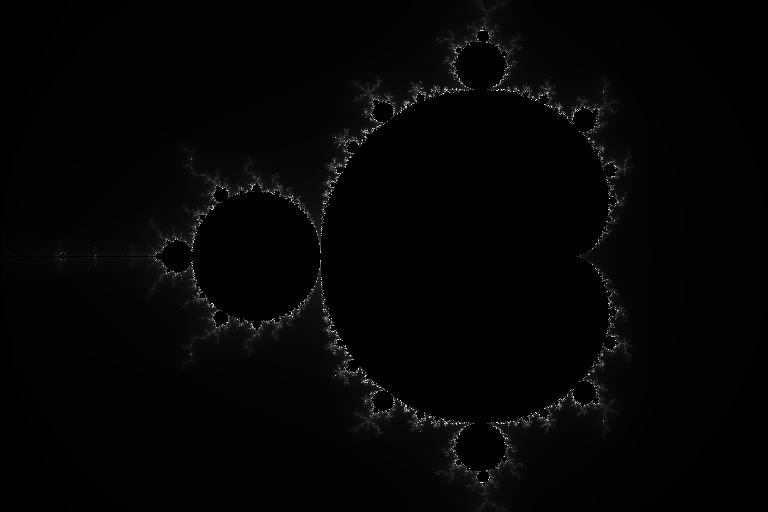

In [14]:
from PIL import Image
from IPython.display import display
display(Image.open("/content/mandelbrot_cpp.ppm"))
